# Clinical data of the patients of the quadrant analysis

This notebook draws the circular plot of clinical data of `metadata/CohortPlotR.ipynb` for the new dataset. It shows the patients kept in `MistySamplingQuadrants.ipynb`, that is the patients with at least one quadrant left after excluding quadrants with 20 epithelial cells or fewer. The annotations come from `sampling_clinical_annotations.csv`: `T_status_summary`, `N_status_summary` and `MSI_status`.

Annotations are linked to patients by the number at the start of their slide code, for example `7451_14_T5` for `CRC-IFN_ACCC_7451`. In two slide codes of the annotation file, two digits of this number are swapped: `16290_15_T7` is patient 16920, and `5627_15_T6` is patient 5267. Patient 9600 has no annotation yet.

This notebook should be run with the root of the repository as working directory.

## Imports

In [77]:
library(dplyr)
library(ggplot2)
library(readr)
library(stringr)
library(ggnewscale)

## Patients and annotations

In [78]:
# Quadrants kept in MistySamplingQuadrants.ipynb
kept_quadrants <- read_csv("./data/sampling/misty_quadrant_lineage_features.csv", col_select = "sample",
                           show_col_types = FALSE)$sample
kept_patients <- unique(str_extract(kept_quadrants, "^CRC-IFN_ACCC_[0-9]+"))
length(kept_patients)

[1] 26

In [79]:
# Patient numbers with swapped digits in the slide codes of the annotation file
slide_number_typos <- c("16290" = "16920", "5627" = "5267")

clini <- read_delim("./data/sampling/sampling_clinical_annotations.csv", delim = ";",
                    locale = locale(decimal_mark = ","), show_col_types = FALSE) %>%
  mutate(patient = paste0("CRC-IFN_ACCC_", recode(str_extract(`slide code`, "^[0-9]+"), !!!slide_number_typos)))

# Patients without annotation stay in the plot, with missing values
clini <- tibble(patient = kept_patients) %>% left_join(clini, by = "patient")
clini %>% filter(is.na(`slide code`)) %>% pull(patient)

[1] "CRC-IFN_ACCC_9600"

In [80]:
"CRC-IFN_ACCC_8392" %in% (clini %>% pull(patient))

[1] FALSE

In [81]:
clini %>% filter(is.na(`T_status_summary`))

patient,patient code,slide code,Sample_ID,sex,age,tumor_location,T_status,T_status_summary,N_status,⋯,intraluminal necrosis,stroma,invasive front,ulcerative necrosis,ratio neutrophils,ratio of NETs,Neutrophil score,OS (years),adjuvant_therapy,neo_adjuvant_therapy
<chr>,<dbl>,<chr>,<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>,⋯,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>
CRC-IFN_ACCC_9600,NA,NA,NA,NA,NA,NA,NA,NA,NA,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA


In [82]:
# Same labels and levels as metadata/CohortPlotR.ipynb, so that each category keeps its color
clini <- clini %>%
  mutate(
    pT = factor(T_status_summary, levels = c("T1", "T2", "T3", "T4")),
    pN = factor(N_status_summary, levels = c("N0", "N1", "N2")),  # "Na" becomes missing
    `MS status` = factor(MSI_status, levels = c("MSI", "MSS"))
  ) %>%
  # Patients in pT order around the circle
  arrange(pT, patient) %>%
  mutate(patient = factor(patient, levels = patient))

clini %>% count(pT, pN, `MS status`)

pT,pN,MS status,n
<fct>,<fct>,<fct>,<int>
T1,N0,MSS,1
T2,N0,MSS,3
T3,N0,MSI,1
T3,N0,MSS,9
T3,N1,MSI,1
T3,N1,MSS,3
T3,N2,MSS,3
T3,NA,MSI,1
T4,N0,MSI,1


## Sex and age

The fractions and the median age are computed over the patients with an annotation.

In [83]:
clini %>%
  filter(!is.na(`slide code`)) %>%
  summarise(
    patients = n(),
    fraction_male = mean(sex == "M"),
    fraction_female = mean(sex == "F"),
    median_age = median(age)
  )

patients,fraction_male,fraction_female,median_age
<int>,<dbl>,<dbl>,<dbl>
25,0.52,0.48,72


## Circular plot

Each segment of the circle is a patient, in T stage order. From the outside to the inside, the rings show the T stage, the N stage and the microsatellite status. Grey marks a missing annotation. The colors are those of `metadata/CohortPlotR.ipynb`.

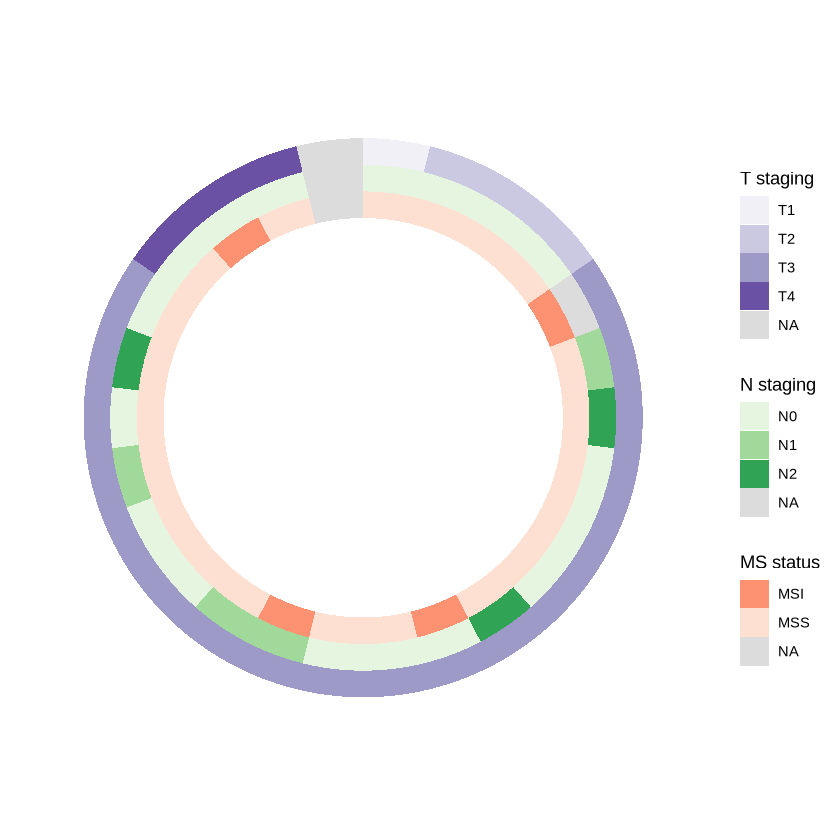

In [84]:
gp <- ggplot(clini, aes(x = patient)) +
  geom_tile(aes(fill = `MS status`, y = 1)) +
  scale_fill_brewer(name = "MS status",
    palette = "Reds",
    direction = -1,
    na.value = "#dcdcdc",
    drop = FALSE,
    guide = guide_legend(order = 3)) +
  new_scale_fill() +
  geom_tile(aes(fill = `pN`, y = 2)) +
  scale_fill_brewer(name = "N staging",
    palette = "Greens",
    na.value = "#dcdcdc",
    drop = FALSE,
    guide = guide_legend(order = 2)) +
  new_scale_fill() +
  scale_fill_brewer(name = "T staging",
    palette = "Purples",
    na.value = "#dcdcdc",
    drop = FALSE,
    guide = guide_legend(order = 1)) +
  geom_tile(aes(fill = `pT`, y = 3)) +
  ylim(-7,3.5) +
  coord_polar() +
  theme_minimal() +
  theme(
    axis.text = element_blank(),
    axis.ticks = element_blank(),
    axis.title = element_blank(),
    panel.grid.major = element_blank(),
  )
dir.create("./figures/sampling", showWarnings = FALSE)
ggsave("./figures/sampling/clinical_data_circular.pdf", plot = gp, width = 6.5, height = 6.5, dpi = 300)
gp